In [1]:
import base
import os    
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

#from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import lqproblem
import optimiser_lqproblem as optimiser_lqproblem
from math import factorial
import pickle

/nfs/home/alifa/myenv/lib/python3.12/site-packages/torch/__init__.py:1305: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at /pytorch/torch/csrc/tensor/python_tensor.cpp:434.)
  _C._set_default_tensor_type(t)


In [2]:
b0 = 1
b1 = 1
b2 = 1
sigma0 = 1
sigma2 = 1

params = {'b0': b0, 'b1': b1, 'b2': b2,
          'sigma0': sigma0, 'sigma2': sigma2, 'X0': 10, 
          'A': 0, 'B': 1, 'C': 0, 'D':0, 'E':1, 'G': 0,
          'T': 1, 'Nt': 1_000}

with open(f'experiment_params.pkl', 'wb') as f:
    pickle.dump(params, f)
    f.close()

env = lqproblem.environment(**params)
env_hjb = lqproblem.environment(**params)
env_hjb_sig = lqproblem.environment(**params)

In [3]:
max_order_x = 5 # truncation of state tensor
max_order_F = 3 # truncation of control tensor
max_order_fn = max(2*max_order_x + 1, 2*max_order_F + 1) # total truncation order of cost functional
# poly_deg = 10

filename = f'lev_control_{max_order_F}_lev_state_{max_order_x}_analytical'

In [4]:
filename

'lev_control_3_lev_state_5_analytical'

In [5]:
# f1, f2, F_HJB = lqproblem.strategy_hjb_sig_functional(env, poly_deg, max_order_x)

In [6]:
np.random.seed(456)
dim = 2

W_sig_expected = lqproblem.fawcett(env, max_order_fn)
    
optimiser_1 = optimiser_lqproblem.Optimiser(env, W_sig_expected, max_order_x = max_order_x, max_order_F = max_order_F)
# F = ta.sig_to_tensor(F, env.dim, order)
# optimiser_1.F = F

In [7]:
# with open(f'F_optimised_lqproblem_{filename}.pkl', 'rb') as f:
#     F_flat = pickle.load(f)
#     f.close()

In [8]:
# Computing optimiser of quadratic polynomial

U, V, p0 = optimiser_1.poly_coef(max_order_x = max_order_x)
F_flat = -(1/2)*np.linalg.inv(U)@V

100%|██████████████████████████████████████████████████████████████████████████████| 105/105 [6:57:52<00:00, 238.78s/it]


In [13]:
F_flat

array([ -38.86268752,  115.80096   ,  -24.25165452, -303.1780068 ,
         17.41773851,    8.83084896,  -29.03654183,  449.6454885 ,
         13.82861669,   37.37079938,   36.88937532,   38.20537228,
         26.21314243,   31.76501943,   -5.13906732])

In [14]:
F = ta.sig_to_tensor(F_flat, env.dim, max_order_F)
optimiser_1.F.value = [F.value[n].clone().detach().requires_grad_() for n in range(max_order_F + 1)]

In [15]:
F

Tensor([-38.86268752377827, [115.80095999736234, -24.25165451627128], [[-303.17800679771204, 17.417738505528973], [8.830848957102944, -29.03654183132676]], [[[449.64548849573384, 13.828616693092386], [37.37079937747427, 36.8893753178661]], [[38.205372278586196, 26.213142431597703], [31.765019433123825, -5.139067323008135]]]])

In [16]:
# alternative method: numerical optimisation

# #np.random.seed(456)
# n_epochs = 1000
# lr = 1

# optimiser_1.train_sgd(n_epochs, lr = lr, max_order_x = max_order_x, max_order_fn = max_order_fn, truncate_fn = True, method='Adam')

# F = optimiser_1.F

# strag_sig = lqproblem.sig_strag_dot(F, order = order)

In [17]:
strag_sig = lqproblem.sig_strag_dot(F, order = max_order_F)

In [19]:
with open(f'F_optimised_lqproblem_{filename}_new.pkl', 'wb') as f:
    pickle.dump(F.flatten(), f)
    f.close()

In [20]:
np.random.seed(123)

nsims = 10

env.simulate(nsims, strag_sig, max_order_F)

/nfs/home/alifa/signature-control/notebooks/../src/lqproblem.py:156: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  strag[nsim] = F.dot(W_sig)


In [21]:
np.random.seed(123)

#nsims = 10000

env_hjb.simulate(nsims, lqproblem.strategy_hjb_feedback, max_order_F, fast = True)

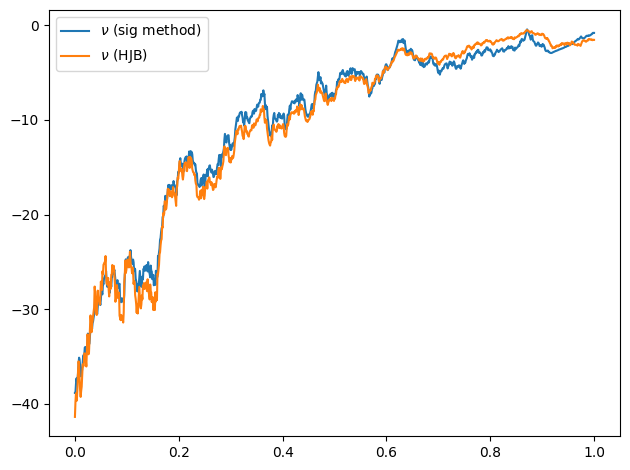

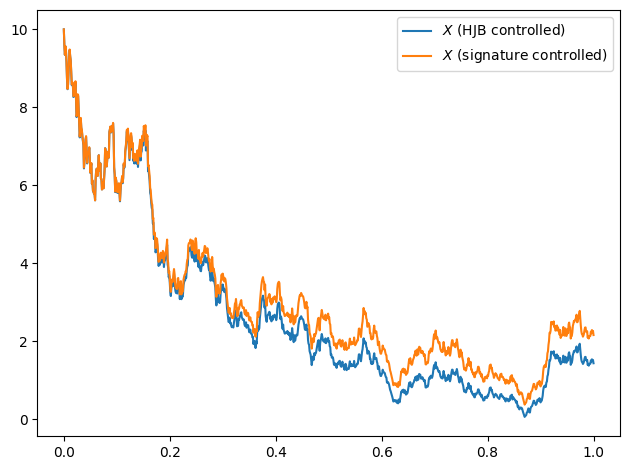

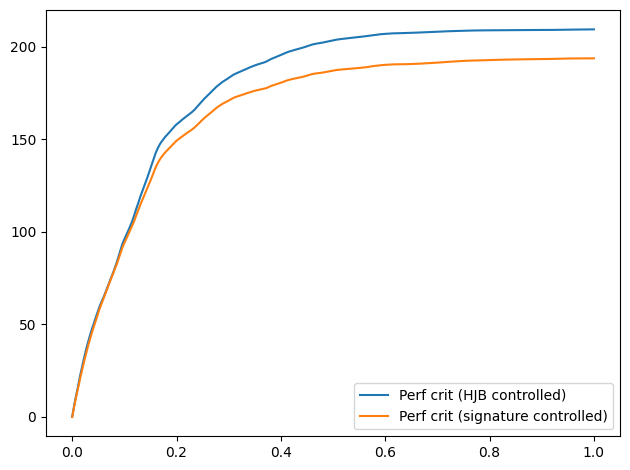

In [22]:
nsim = 0

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$ (sig method)')
plt.plot(env.timesteps, env_hjb.nu[:,nsim], label=r'$\nu$ (HJB)')
#plt.plot(env.timesteps, env_hjb_sig.nu[:,nsim], label=r'$\nu$ (HJB sig representation)', linestyle='-.')
#plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env_hjb.X[:,nsim], label=r'$X$ (HJB controlled)')
plt.plot(env.timesteps, env.X[:, nsim], label=r'$X$ (signature controlled)')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env_hjb.run_crit[:,nsim], label=r'Perf crit (HJB controlled)')
plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit (signature controlled)')
plt.legend()
plt.tight_layout()
plt.show()

In [23]:
print(f'Performance criterion\nSig: {env.performance.mean()}')

Performance criterion
Sig: 449.6856675015489


In [24]:
print(f'Performance criterion\nHJB: {env_hjb.performance.mean()}')

Performance criterion
HJB: 426.4672881604432
